# Mixed layer depth in ACCESS models and observations

Related issue: https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/38

Requires access to `/g/data/av17`

In [1]:
# These first two cells must be in all notebooks!
# It allows us to run all the notebooks at once, this cell has a tag "parameters" which allows us to pass in 
# arguments externally using papermill (see mkfigs.sh for details)

# Set esm_file to the datastore for the main experiment of interest

# Second experiment to compare against (set to None to skip the comparison)
esm_file_compare = None
esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-00532b88/datastore.json"
# esm_file = "/g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-27-07-2026-PD-control/cm3-datastore/cm3-datastore.json"

# What physical field you want, in CF terms (stays the same across models)
variable_standard_name = "Ocean Mixed Layer Thickness Defined by Sigma T"

# Fallback variable name to use if the catalog doesn’t expose standard_name
fallback_variable_names = ["mlotst", "mld", "mixed_layer_depth", "mixed_layer_thickness"]

# Frequency depends on the datastore you’re using:
data_frequency = "1mon"

# papermill settings. *No need to modify these if running interactively.* 
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory 
nbname = None                          # notebook name

In [2]:
# Parameters
esm_file = "/g/data/tm70/cyb561/esm_datastores/ol01_full/MC_8km_jra_ryf-test2-expt-c349f800/datastore.json"
papermill = True
cwd = "/g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-92f87ab/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/"
nbname = "MLD.ipynb"


In [3]:
if not papermill: 
    import nci_ipynb, os  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter
mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)
from exptdata_access import get_experiment_info, guess_experiment_from_esm_file
from model_agnostic import get_lon_lat_from_catalog, select_variable, patch_broken_conda_env
patch_broken_conda_env()  # conda env workaround for analysis3-26.03+; no-op on healthy envs
# Infer model information from the datastore path
expt_key, info = guess_experiment_from_esm_file(esm_file)
model_name = info["model"]             # OM3 or CM3

In [4]:
import xarray as xr
import cf_xarray as cfxr
import cf_xarray.units
import pint_xarray
from pint import application_registry as ureg
import intake
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
from distributed import Client
import cftime
import os
import matplotlib.pyplot as plt
import cmocean as cm
import cartopy.crs as ccrs
import cartopy.feature as cft
from textwrap import wrap
xr.set_options(keep_attrs=True);  # cf_xarray works best when xarray keeps attributes by default

### Define plot function

In [5]:
blue_marble = plt.imread('/g/data/ik11/grids/BlueMarble.tiff')
blue_marble_extent = (-180, 180, -90, 90)

In [6]:
def plot(dat, title=None, **kwargs):
    if title is None:
        title = dat.attrs['long_name']
    fig = plt.figure(figsize=(12, 6))
    ax = plt.axes(projection=ccrs.Robinson(central_longitude=-100))
    dat.plot.contourf(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cbar_kwargs={"label": "\n".join(wrap(f"{dat.attrs['long_name']} [{dat.attrs['units']}]", 45)),
                     "fraction": 0.03, "aspect": 15, "shrink": 0.7},
        **kwargs
    )
    
    # Add blue marble land:
    ax.imshow(
        blue_marble, extent=blue_marble_extent, transform=ccrs.PlateCarree(), origin="upper"
    )
    
    plt.title(title);

In [7]:
def seasonal_mean(da, months, weights):
    # Select months, then do time-weighted mean
    da_m = da.where(da["time"].dt.month.isin(months), drop=True)
    w_m  = weights.where(da["time"].dt.month.isin(months), drop=True)
    return da_m.weighted(w_m).mean("time")

### Load and plot data from ACCESS-OM3

In [8]:
from exptdata_access import get_exptname_from_path
exptname=get_exptname_from_path(esm_file)
print("Experiment name:", exptname)

datastore = intake.open_esm_datastore(
    esm_file,
    columns_with_iterables=[
        "variable",
        "variable_long_name",
        "variable_standard_name",
        "variable_cell_methods",
        "variable_units"
    ]
)

Experiment name: MC_8km_jra_ryf-test2-expt-c349f800


In [9]:
try:
    from distributed import get_client
    get_client().close()
except ValueError:
    pass
if "client" in globals():
    del client

da_model = select_variable(
    datastore,
    variable_standard_name,
    fallback_variable_names,
    data_frequency=data_frequency,
)
print("Selected variable:", da_model.name)
print("dims:", da_model.dims)

CF-based lookup failed: ValueError('No entries found for this CF standard_name.')


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14f5e57ccd40>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14f5e57ab1a0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:66: UserWarning: An error occurred while loading the GDAC data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14f5e51b9e20>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:91: UserWarning: An error occurred while loading the ERDDAP index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14f5e51b16a0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:107: UserWarning: An error occurred while loading the GDAC index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14f5e57ab110>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'argo' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14f5e51bbc50>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14f5e4172d80>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


Selected variable via fallback name: mlotst
Selected variable: mlotst
dims: ('time', 'yh', 'xh')


In [10]:
# Discover lon/lat from the catalog (using the helper we wrote earlier)
lon, lat = get_lon_lat_from_catalog(datastore)

# Ensure model_all has CF longitude/latitude coords
try:
    # If CF coords already exist, just use them
    _ = da_model.cf["longitude"]
    _ = da_model.cf["latitude"]
    model_all = da_model
    print("Using existing CF longitude/latitude on da_model.")
except KeyError:
    # Otherwise, attach the lon/lat we discovered
    model_all = da_model.cf.assign_coords(
        {
            "longitude": lon,
            "latitude": lat,
        }
    )
    print("Attached longitude/latitude from catalog grid variables.")

print("model_all dims:", model_all.dims)

Using existing CF longitude/latitude on da_model.
model_all dims: ('time', 'yh', 'xh')


In [11]:
# Averaging window: last NYEARS complete years, or an explicit [first, last] period
averaging_period = None   # e.g. [1908, 1909]; None = automatic
NYEARS = 2
from model_agnostic import years_window, year_slice

In [12]:
if exptname == "25km-iaf-test-for-AK-expt-7df5ef4c":
    model_all = model_all.isel(yh=slice(10, None))
    lon = lon.isel(yh=slice(10, None))
    lat = lat.isel(yh=slice(10, None))

In [13]:
# Inspect full time coverage
print("Full model time range:", model_all.time.values[0], "→", model_all.time.values[-1])

# Choose the window on the native time axis, before any calendar conversion
# (converting daily noleap data to proleptic_gregorian would make leap years look incomplete)
om3_window = years_window(model_all.time, NYEARS, period=averaging_period)
print("Averaging window:", om3_window)
period_label = f"{om3_window[0]}-{om3_window[1]}"

# Restrict model to this window, then put it on a common calendar
model_window = model_all.sel(time=year_slice(om3_window))
model_window = model_window.convert_calendar("proleptic_gregorian", use_cftime=True)
print("Windowed dims:", model_window.dims)

Full model time range: 1900-01-16 12:00:00 → 1909-12-16 12:00:00
Averaging window: (1908, 1909)
Windowed dims: ('time', 'yh', 'xh')


In [14]:
# weights = days in each timestep's month
w = model_window["time"].dt.days_in_month

In [15]:
%%time
model_JFM_mean = seasonal_mean(model_window, [1, 2, 3], w).compute()
model_JAS_mean = seasonal_mean(model_window, [7, 8, 9], w).compute()

CPU times: user 15.5 s, sys: 1.49 s, total: 17 s
Wall time: 21.1 s


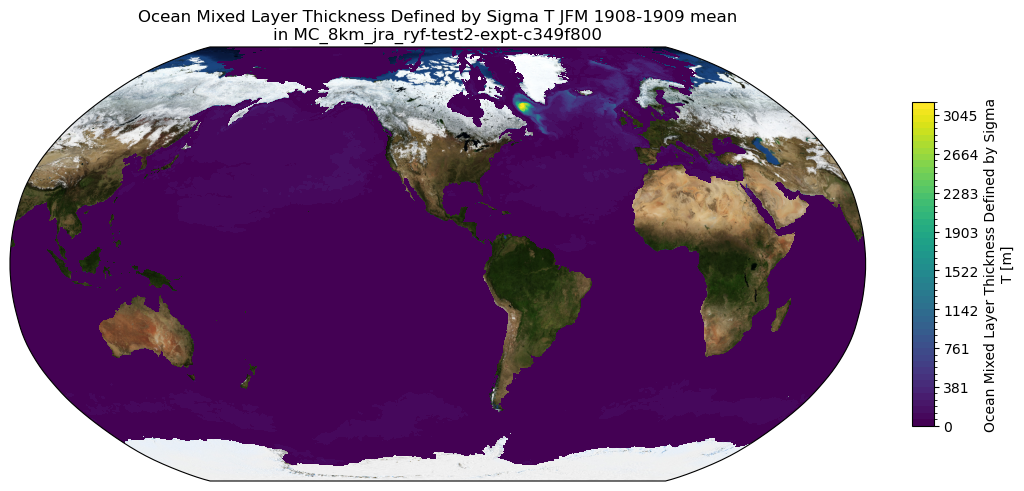

In [16]:
plot(model_JFM_mean,
    levels=51,
    vmin=0,
    vmax=None,
    cmap='viridis',
    title=f"{model_window.attrs['long_name']} JFM {period_label} mean\nin {exptname}"
    )

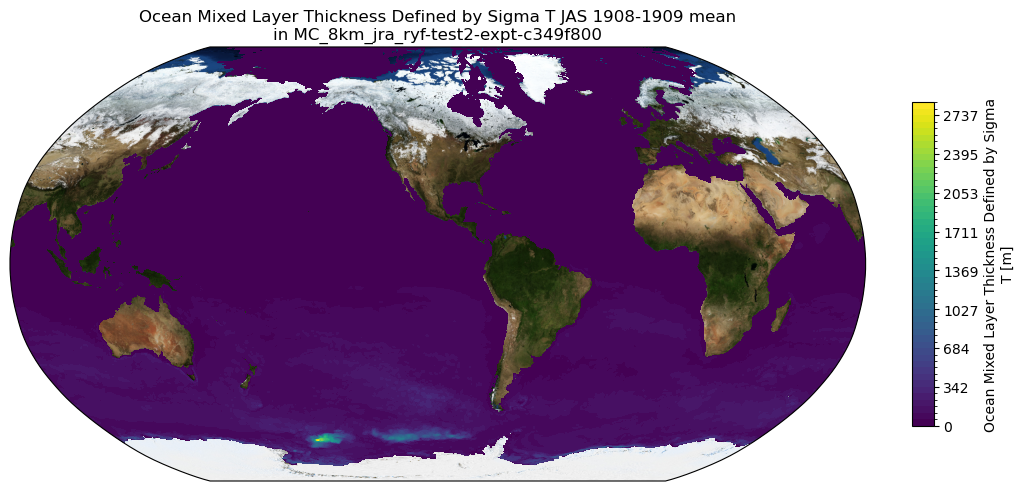

In [17]:
plot(model_JAS_mean,
    levels=51,
    vmin=0,
    vmax=None,
    cmap='viridis',
    title=f"{model_window.attrs['long_name']} JAS {period_label} mean\nin {exptname}"
    )

Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-92f87ab/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/MLD_01.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-92f87ab/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/MLD.md


Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-92f87ab/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/MLD.md successfully.


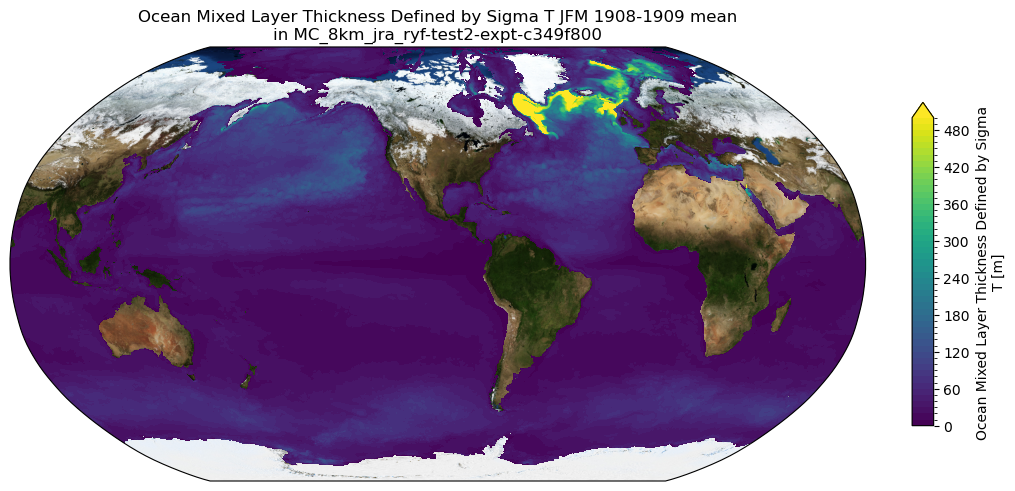

In [18]:
plot(model_JFM_mean,
    levels=51,
    vmin=0,
    vmax=500,
    extend="max",
    cmap='viridis',
    title=f"{model_window.attrs['long_name']} JFM {period_label} mean\nin {exptname}"
    )
mkmd.savefig(plt.gcf(), "Mixed Layer Depth: Model JFM", "Ocean Mixed Layer Depth JFM. GitHub issue: [#38](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/38) — Time-max mixed layer depth maps")

Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-92f87ab/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/MLD_02.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-92f87ab/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/MLD.md
Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-92f87ab/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/MLD.md successfully.


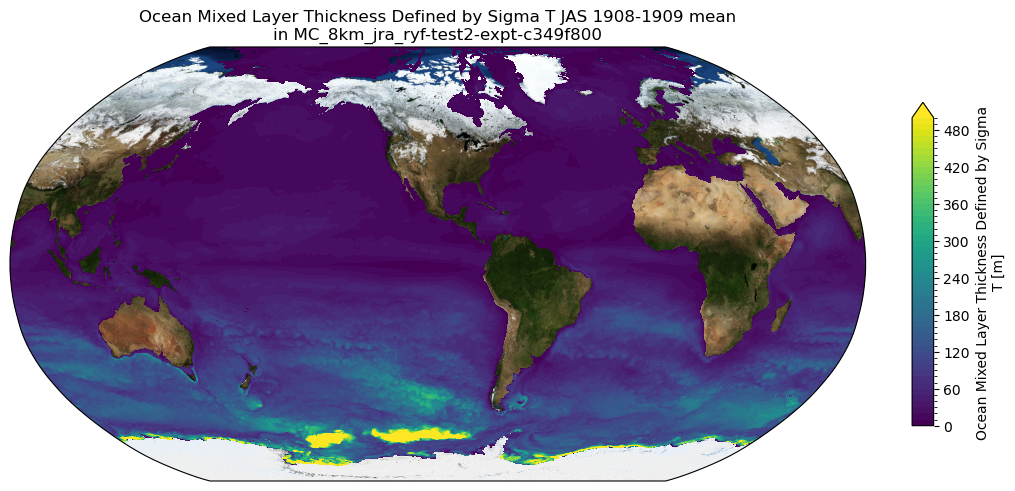

In [19]:
plot(model_JAS_mean,
    levels=51,
    vmin=0,
    vmax=500,
    extend="max",
    cmap='viridis',
    title=f"{model_window.attrs['long_name']} JAS {period_label} mean\nin {exptname}"
    )
mkmd.savefig(plt.gcf(), "Mixed Layer Depth: Model JAS", "Ocean Mixed Layer Depth JAS. GitHub issue: [#38](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/38) — Time-max mixed layer depth maps")

### Load and plot data from MC comparison experiment

In [20]:
if esm_file_compare is not None:
    exptname_compare = get_exptname_from_path(esm_file_compare)
    print("Comparison experiment name:", exptname_compare)

    datastore_compare = intake.open_esm_datastore(
        esm_file_compare,
        columns_with_iterables=[
            "variable",
            "variable_long_name",
            "variable_standard_name",
            "variable_cell_methods",
            "variable_units"
        ]
    )

    da_model_compare = select_variable(
        datastore_compare,
        variable_standard_name,
        fallback_variable_names,
        data_frequency=data_frequency,
    )
    print("Selected variable:", da_model_compare.name)
    print("dims:", da_model_compare.dims)

In [21]:
if esm_file_compare is not None:
    # Discover lon/lat from the comparison catalog
    lon_compare, lat_compare = get_lon_lat_from_catalog(datastore_compare)

    try:
        _ = da_model_compare.cf["longitude"]
        _ = da_model_compare.cf["latitude"]
        model_all_compare = da_model_compare
        print("Using existing CF longitude/latitude on da_model_compare.")
    except KeyError:
        model_all_compare = da_model_compare.cf.assign_coords(
            {
                "longitude": lon_compare,
                "latitude": lat_compare,
            }
        )
        print("Attached longitude/latitude from catalog grid variables.")

    print("model_all_compare dims:", model_all_compare.dims)

In [22]:
if esm_file_compare is not None:
    print("Full comparison model time range:",
          model_all_compare.time.values[0], "→", model_all_compare.time.values[-1])

    # Use the same model years as the main experiment where the comparison run has them, so
    # differences between the two are not confounded by different periods. years_window warns
    # if only part is covered, and falls back to the comparison run's first NYEARS complete
    # years (with a warning) if none is. Chosen on the native time axis, before any conversion.
    compare_window = years_window(model_all_compare.time, NYEARS, within=om3_window, fallback="last")
    print("Comparison averaging window:", compare_window)
    period_label_compare = f"{compare_window[0]}-{compare_window[1]}"

    model_window_compare = model_all_compare.sel(time=year_slice(compare_window))
    model_window_compare = model_window_compare.convert_calendar("proleptic_gregorian", use_cftime=True)
    print("Windowed dims:", model_window_compare.dims)

    # weights = days in each timestep's month
    w_compare = model_window_compare["time"].dt.days_in_month

    model_compare_JFM_mean = seasonal_mean(model_window_compare, [1, 2, 3], w_compare).compute()
    model_compare_JAS_mean = seasonal_mean(model_window_compare, [7, 8, 9], w_compare).compute()

In [23]:
if esm_file_compare is not None:
    plot(model_compare_JFM_mean,
        levels=51,
        vmin=0,
        vmax=500,
        extend="max",
        cmap='viridis',
        title=f"{model_window_compare.attrs['long_name']} JFM {period_label_compare} mean\nin {exptname_compare}"
        )
    mkmd.savefig(plt.gcf(), "Mixed Layer Depth: Comparison JFM", "Ocean Mixed Layer Depth JFM (comparison experiment). GitHub issue: [#38](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/38) — Time-max mixed layer depth maps")

In [24]:
if esm_file_compare is not None:
    plot(model_compare_JAS_mean,
        levels=51,
        vmin=0,
        vmax=500,
        extend="max",
        cmap='viridis',
        title=f"{model_window_compare.attrs['long_name']} JAS {period_label_compare} mean\nin {exptname_compare}"
        )
    mkmd.savefig(plt.gcf(), "Mixed Layer Depth: Comparison JAS", "Ocean Mixed Layer Depth JAS (comparison experiment). GitHub issue: [#38](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/38) — Time-max mixed layer depth maps")

### Load and plot obs data from DeBoyer Montegut (2023)
https://doi.org/10.17882/91774

In [25]:
MLDobs = xr.open_dataset('/g/data/av17/access-nri/OM3/MLD-DeBoyerMontegut2023/mld_dr003_ref10m_v2023.nc')['mld_dr003']
MLDobs.attrs['units'] = MLDobs.attrs['unit']  # fix so plot works

# TODO: append copy of westernmost data to eastern end to avoid gap in plot

In [26]:
# small BUG: mean of monthly means is not mean of days in that month (eg Feb gets slightly more heavily weighted)
MLDobs_JFM_mean = MLDobs.isel(time=[0, 1, 2]).mean('time').load()
MLDobs_JAS_mean = MLDobs.isel(time=[6, 7, 8]).mean('time').load()

Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-92f87ab/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/MLD_03.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-92f87ab/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/MLD.md
Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-92f87ab/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/MLD.md successfully.


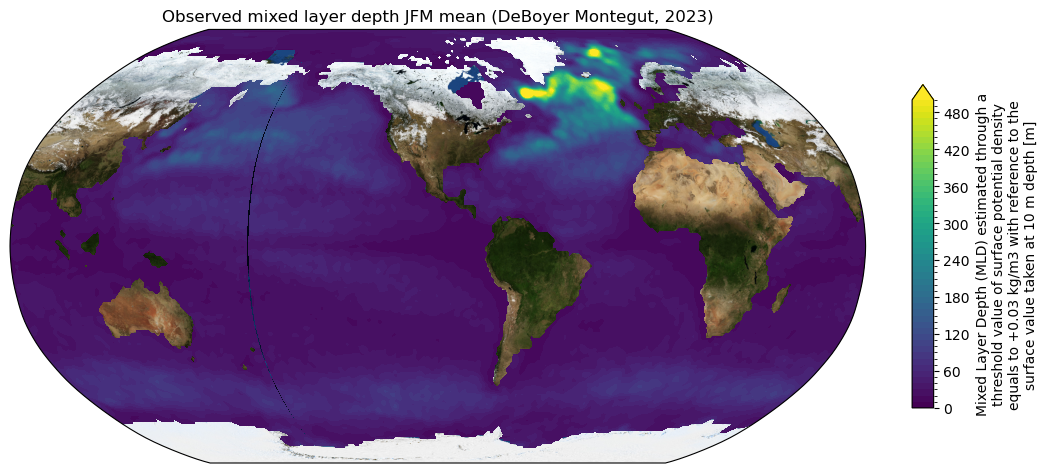

In [27]:
plot(MLDobs_JFM_mean,
    levels=51,
    vmin=0,
    vmax=500,
    extend="max",
    cmap='viridis',
    title=f"Observed mixed layer depth JFM mean (DeBoyer Montegut, 2023)"
    )
mkmd.savefig(plt.gcf(), "Mixed Layer Depth: Observed JFM", "Observed ocean Mixed Layer Depth JFM. GitHub issue: [#38](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/38) — Time-max mixed layer depth maps")

Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-92f87ab/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/MLD_04.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-92f87ab/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/MLD.md
Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-92f87ab/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/MLD.md successfully.


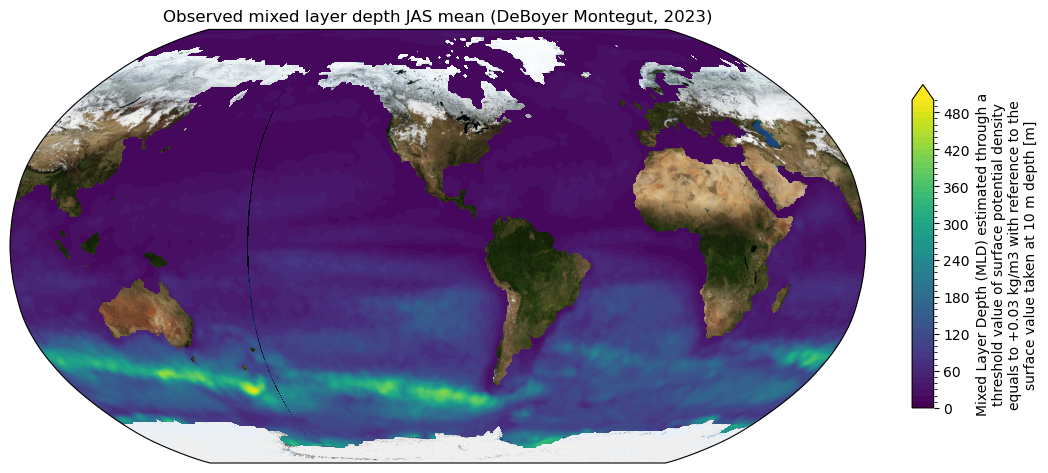

In [28]:
plot(MLDobs_JAS_mean,
    levels=51,
    vmin=0,
    vmax=500,
    extend="max",
    cmap='viridis',
    title=f"Observed mixed layer depth JAS mean (DeBoyer Montegut, 2023)"
    )
mkmd.savefig(plt.gcf(), "Mixed Layer Depth: Observed JAS", "Observed ocean Mixed Layer Depth JAS. GitHub issue: [#38](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/38) — Time-max mixed layer depth maps")